In [ ]:
import marimo as mo

# Lecture 2: What makes reconnection fast?

In Lecture 1 we checked the Sweet–Parker conservation arguments against nonlinear multi-fluid
simulations of the GEM reconnection problem. Here we ask what it means for reconnection to be
"fast," and use an Ohm's law analysis of the same simulations to find out what makes it fast.
The setup cells below (units, helper functions, and data loading) are the same as in Lecture 1.

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import postgkyl as pg
from postgkyl.diagnostics.mom import five_moment, ten_moment
import numpy as np

In [ ]:
# Helper function for computing vector potential
def calc_psi2d(fx, fy, dx=1, dy=1):#solenoidal flows
	'''
	Calcualte psi by integrating dpsi = -fy*dx + fx*dy, psi[0,0]=0.
	Notes: 
		1. (fx=dpsi/dy,fy=-dpsi/dx) is called Hamiltonian gradient of psi, and	contours of psi give vector field (fx, fy);
		2. div(f)=0
	'''
	ny,nx=fx.shape
	psi=np.zeros((ny,nx))
	for jx in range(1,nx):
		psi[0,jx]=psi[0,jx-1]-fy[0,jx]*dx
	for jy in range(1,ny):
		psi[jy,:]=psi[jy-1,:]+fx[jy,:]*dy
	# since f = rot(A) gives extra restraints on f (e.g., div(f)=0)
	# it makes sense that information provided by fy[1:nx,:] is useless here
	return psi

### Defining our units

When running simulations, it is often convenient to define a set of normalized units in which to perform the simulation. Many physical constants, such as the permittivity of free space, $\epsilon_0 = 8.85 \times 10^{-12} F/m$, or the actual electron and proton mass, $m_e = 9.11\times 10^{-31} kg, m_p = 1.67\times 10^{-27}kg$ respectively, could lead to enhanced truncation error due to finite precision arithmetic if we carried around the physical values of these constants in our simulations.

Below I define the units of the electron-ion multi-fluid magnetic reconnection simulations we have performed.

In [ ]:
# Physical constants and derived parameters
gas_gamma = 5.0 / 3.0 # Adiabatic index.
epsilon0 = 1.0 # Permittivity of free space.
mu0 = 1.0 # Permeability of free space.
light_speed = 1.0/np.sqrt(epsilon0*mu0) # Speed of light. 
mass_ion = 100.0 # Ion mass.
charge_ion = 1.0 # Ion charge.
mass_elc = 1.0 # Electron mass.
charge_elc = -1.0 # Electron charge.
Ti_over_Te = 5.0 # Ion temperature / electron temperature.
n0 = 1.0 # Reference number density.
nb_over_n0 = 0.2 # Background number density / reference number density.
wpi = np.sqrt(charge_ion**2 * n0 / (epsilon0 * mass_ion)) # Ion plasma frequency. 
wpe = np.sqrt(charge_ion**2 * n0 / (epsilon0 * mass_elc)) # Electron plasma frequency. 
di = light_speed/wpi # Ion inertial length. 
de = light_speed/wpe # Electron inertial length. 
B0 = 0.5 # Reference magnetic field strength. Sets ratio of vAe/c. 
beta = 1.0 # Plasma beta.
omega_ci = charge_ion * B0 / mass_ion # Ion cyclotron frequency. 
vA0 = B0/np.sqrt(mu0*n0*mass_ion) # Reference Alfven speed. 
vA_up = B0/np.sqrt(mu0*nb_over_n0*mass_ion) # Upstream reference Alfven speed from background density. 
Lambda_ee = 2.0e5 # Plasma parameter for computing collision time. 
Ti_frac = Ti_over_Te / (1.0 + Ti_over_Te) # Fraction of total temperature from ions.
Te_frac = 1.0 / (1.0 + Ti_over_Te) # Fraction of total temperature from electrons.
T_tot = beta * (B0 * B0) / 2.0 / n0 # Total temperature.
T_elc_ref = T_tot*Te_frac # Reference electron temperature.

In [ ]:
import os
from pathlib import Path

# Simulation output lives in ../runs next to this notebook, or wherever GEM_DATA_DIR points
DATA_DIR = Path(os.environ.get("GEM_DATA_DIR", mo.notebook_dir() / ".." / "runs"))

def get_Gdata(pre, frame):
    data_elc = pg.load(str(DATA_DIR / ("%s-elc_%d.gkyl" % (pre, frame))))
    data_ion = pg.load(str(DATA_DIR / ("%s-ion_%d.gkyl" % (pre, frame))))
    data_field = pg.load(str(DATA_DIR / ("%s-field_%d.gkyl" % (pre, frame))))

    return data_elc, data_ion, data_field

In [ ]:
def read_data(data_elc, data_ion, data_field):
    fluid_elc = data_elc.get_values()
    fluid_ion = data_ion.get_values()  
    field = data_field.get_values()  

    # Same grid for all electrons, ions, and EM fields
    # Center the grid values (build a new list so the GData's own cell edges are untouched)
    coords = [0.5*(g[:-1] + g[1:]) for g in data_elc.get_grid()]

    return coords, fluid_elc, fluid_ion, field

In [ ]:
# Grid size (the same for both simulations)
_coords, _fluid_elc, fluid_ion_0, _field = read_data(*get_Gdata('resistive_gem_mass100/rt_5m_resistive_gem', 0))
Nx_1, Ny_1 = fluid_ion_0.shape[0], fluid_ion_0.shape[1]

### So what does it even mean for the reconnection to be fast?

We have now shown that our simulations obey the Sweet-Parker scalings. Good! $\texttt{Gkeyll}$ obeys conservation of mass and energy! But wait a minute, when we derived the Sweet-Parker scaling before we found the reconnection rate before, it scaled with the resistivity, meaning the in-flow velocity should be related to the Alfvén velocity by the resistivity. We know that,
\begin{align}
u_y \sim u_x S^{-\frac{1}{2}}, \quad S = \frac{L V_A}{\eta}
\end{align}
Let's estimate this from our resistive 5 moment calculation. Given the choice of plasma parameter, $\Lambda$, and $L \sim 10 d_i$, we should get a Lundquist number of $\sim 10^5$ (try plugging in all the values for the code units; since the Lundquist number is a normalized quantity you can just use the code unit values for everything, $L, V_A, \eta$, and safely estimate the Lundquist number).

Well.. that is much slower than we are finding right? So what is the actual reconnection rate? We can compute this by either evaluating the reconnecting electric field $E_z$ at the X-point, or computing the rate of change of the vector potential. Either way, we see that in fact the rate is actually $\sim 0.1 V_A$, **much faster** than what Sweet and Parker estimated! In fact, this rate is the same rate fully kinetic simulations which directly solve the Vlasov equation obtain!

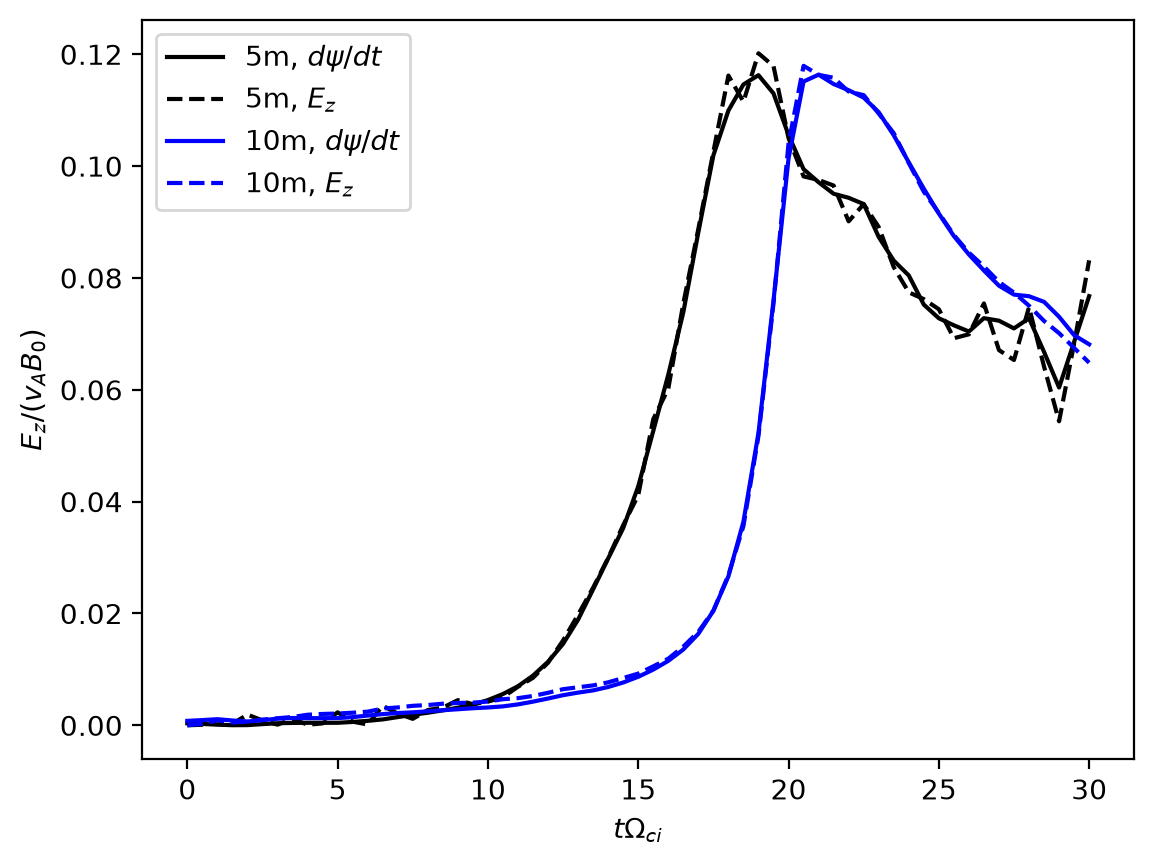

In [ ]:
# Compute the reconnection rate
def compute_flux(pre, frame):
    data_elc, data_ion, data_field = get_Gdata(pre, frame)
    r_coords, r_fluid_elc, r_fluid_ion, r_field = read_data(data_elc, data_ion, data_field)
    EzX = r_field[int(Nx_1 / 2), int(Ny_1 / 2), 2]  # Fetch Ez at X point
    dx = r_coords[0][1] - r_coords[0][0]
    dy = r_coords[1][1] - r_coords[1][0]  # Compute vector potential at X point.
    psi = np.zeros((Ny_1, Nx_1))
    psi = calc_psi2d(r_field[..., 3].transpose(), r_field[..., 4].transpose(), dx, dy)
    psiX = psi[int(Ny_1 / 2), int(Nx_1 / 2)]
    psi0 = np.max(np.abs(psi))
    return (psiX, psi0, EzX)
num_frames = 61
psiX_5m = np.zeros(num_frames)
psi0_5m = np.zeros(num_frames)
EzX_5m = np.zeros(num_frames)
psiX_10m = np.zeros(num_frames)
psi0_10m = np.zeros(num_frames)
EzX_10m = np.zeros(num_frames)
t = np.linspace(0, 30 / omega_ci, num_frames)
rate_fac = 1 / (B0 * vA_up)
for i in range(0, num_frames):
    psiX_5m[i], psi0_5m[i], EzX_5m[i] = compute_flux('resistive_gem_mass100/rt_5m_resistive_gem', i)
    psiX_10m[i], psi0_10m[i], EzX_10m[i] = compute_flux('10m_gem_mass100/rt_10m_gem', i)
psi_diff_5m = np.abs(psi0_5m - psiX_5m)
dpsi_dt_5m = np.gradient(psi_diff_5m, t)  # Compute the flux at the X-point in resistive 5 moment simulation
psi_diff_10m = np.abs(psi0_10m - psiX_10m)
dpsi_dt_10m = np.gradient(psi_diff_10m, t)  # Compute the flux at the X-point in 10 moment simulation
plt.figure()
plt.plot(t * omega_ci, np.abs(dpsi_dt_5m) * rate_fac, 'k-', label='5m, $d\\psi/dt$')
# We can either use Ez or the time derivative of the vector potential psi to estimate the reconnection rate. 
plt.plot(t * omega_ci, np.abs(EzX_5m) * rate_fac, 'k--', label='5m, $E_z$')
plt.plot(t * omega_ci, np.abs(dpsi_dt_10m) * rate_fac, 'b-', label='10m, $d\\psi/dt$')
plt.plot(t * omega_ci, np.abs(EzX_10m) * rate_fac, 'b--', label='10m, $E_z$')
plt.xlabel('$t \\Omega_{ci}$')
plt.ylabel('$E_z/(v_A B_0)$')
plt.legend(loc='best')
plt.show()

### Explaining "fast" reconnection with the Ohm's Law

Let's now look at why the reconnection is faster in our multi-fluid simulations by answering the following question: what is different about our simulation compared to the Sweet-Parker argument?

1.   MHD cannot get fast reconnection. We had to add at least two-fluid effects to include dispersive waves.
2.   Sweet-Parker assumed resistivity set the $\delta/L$ scaling; that's not true in our simulations. The layer width is bigger than if we only had resistivity.
3.   The layer is not genuinely incompressible. We need compressibility so that the plasma can shock and push plasma in the outflow.
4.   The conservation of energy argument is missing additional energy flux terms which move energy into the layer.

> **Pause and think:** pick an answer before reading on.

Given this (key) difference between the Sweet-Parker argument and our simulations, let's look at the effective Ohm's Law for our plasma. Unlike in MHD, where the Ohm's Law prescribes the electric field,
\begin{align}
\mathbf{E}_{MHD} = \mathbf{u} \times \mathbf{B} + \eta \mathbf{J}
\end{align}
we solved Maxwell's equations coupled to our multi-fluid system. Nevertheless, we can still utilize the electron momentum equation to obtain an Ohm's Law-like expression for the electric field:
\begin{align}
\mathbf{E} = \frac{m_e}{q_e \rho_e} \left (\frac{\partial \rho_e \mathbf{u}_e}{\partial t} + \nabla \cdot \left ( \rho_e \mathbf{u}_e \mathbf{u}_e + \mathbf{P}_e \right ) -\frac{q_e}{m_e} \rho_e \mathbf{u}_e \times \mathbf{B} - \mathbf{R} \right )
\end{align}
which is often simplified using conservation of mass as
\begin{align}
\mathbf{E} = \frac{m_e}{q_e} \left (\frac{\partial \mathbf{u}_e}{\partial t} + \mathbf{u}_e \cdot \nabla  \mathbf{u}_e + \frac{1}{\rho_e} \nabla \cdot \mathbf{P}_e \right ) -\mathbf{u}_e \times \mathbf{B} - \frac{m_e}{q_e \rho_e} \mathbf{R}.
\end{align}

In the two-dimensional geometry of this magnetic reconnection setup, the important electric field for supporting the reconnection is $E_z$. So our Ohm's Law in general is
\begin{align}
E_z = \frac{m_e}{q_e} \left (\underbrace{\frac{\partial u_{z_e}}{\partial t} + u_{x_e} \frac{\partial u_{z_e}}{\partial x} + u_{y_e} \frac{\partial u_{z_e}}{\partial y}}_{Inertia} + \frac{1}{\rho_e} \left [\frac{\partial P_{xz_e}}{\partial x} + \frac{\partial P_{yz_e}}{\partial y} \right ] \right ) - \underbrace{\left (u_{x_e} B_y - u_{y_e} B_x \right )}_{Hall} - \underbrace{\frac{m_e}{q_e \rho_e} R_z}_{Resistivity}.
\end{align}
with the off-diagonal pressure tensor components vanishing for the 5 moment simulations, and no resistive contribution to the 10 moment simulations.

Which of these terms can break field-lines?

1.   Only resistivity.
2.   Resistivity, inertia, and Hall term can break field lines (all the terms in 5 moment).
3.   Resistivity and the off-diagonal Pressure Tensor components.
4.   All of the terms can break field lines.

> **Pause and think:** pick an answer before reading on.

In [ ]:
def fdx_2d_8th_order(data, dx, Nx, Ny):
    diff_data = np.zeros((Nx, Ny))
    for i in range(4, Nx-4):
        for j in range(4, Ny-4):    
            diff_data[i,j] = (-data[i+4, j]/280.0 + data[i+3, j]*4.0/105.0 - data[i+2, j]/5.0 + data[i+1, j]*4.0/5.0 \
                - data[i-1, j]*4.0/5.0 + data[i-2, j]/5.0 - data[i-3, j]*4.0/105.0 + data[i-4, j]/280.0) / dx
    return diff_data

def fdy_2d_8th_order(data, dy, Nx, Ny):
    diff_data = np.zeros((Nx, Ny))
    for i in range(4, Nx-4):
        for j in range(4, Ny-4):    
            diff_data[i,j] = (-data[i, j+4]/280.0 + data[i, j+3]*4.0/105.0 - data[i, j+2]/5.0 + data[i, j+1]*4.0/5.0 \
                - data[i, j-1]*4.0/5.0 + data[i, j-2]/5.0 - data[i, j-3]*4.0/105.0 + data[i, j-4]/280.0) / dy
    return diff_data

In [ ]:
def ohm_10m(frame):
    data_elc, data_ion, data_field = get_Gdata("10m_gem_mass100/rt_10m_gem", frame)
    r_coords, r_fluid_elc, r_fluid_ion, r_field = read_data(data_elc, data_ion, data_field)
    Nx = r_fluid_ion.shape[0]
    Ny = r_fluid_ion.shape[1]    
    dx = r_coords[0][1] - r_coords[0][0]
    dy = r_coords[1][1] - r_coords[1][0]
    # Fetch mass density, in-plane momentum, out-of-plane velocity, and pressure tensor Pij
    rho_elc = r_fluid_elc[...,0]
    rhoux_elc = r_fluid_elc[..., 1]
    rhouy_elc = r_fluid_elc[..., 2]
    uz_elc = five_moment.zvel(data_elc).get_values()
    uz_elc = np.squeeze(uz_elc)
    Pij_elc = np.concatenate([getattr(ten_moment, _c)(data_elc).get_values() for _c in ("pxx", "pxy", "pxz", "pyy", "pyz", "pzz")], axis=-1)
    Pxz_elc = Pij_elc[...,2]
    Pyz_elc = Pij_elc[...,4]

    # Compute 1/(q/m rho) div(P_iz) and 1/(q/m rho) (rhou_x du_z/dx + rhou_y du_z/dy)
    divRxz_elc = fdx_2d_8th_order(uz_elc, dx, Nx, Ny)
    divRyz_elc = fdy_2d_8th_order(uz_elc, dy, Nx, Ny)
    divPxz_elc = fdx_2d_8th_order(Pxz_elc, dx, Nx, Ny)
    divPyz_elc = fdy_2d_8th_order(Pyz_elc, dy, Nx, Ny)    

    divRxz_elc = rhoux_elc*divRxz_elc/(charge_elc/mass_elc*rho_elc)
    divRyz_elc = rhouy_elc*divRyz_elc/(charge_elc/mass_elc*rho_elc) 
    divPxz_elc = divPxz_elc/(charge_elc/mass_elc*rho_elc)
    divPyz_elc = divPyz_elc/(charge_elc/mass_elc*rho_elc) 

    # Compute Hall term
    Bx = r_field[...,3]
    By = r_field[...,4]
    hallz = np.zeros((Nx, Ny))
    hallz = charge_elc/mass_elc*(rhoux_elc*By - rhouy_elc*Bx)/(charge_elc/mass_elc*rho_elc)

    # Fetch Ez
    Ez = r_field[...,2]

    return r_coords, Ez, hallz, divPxz_elc, divPyz_elc, divRxz_elc, divRyz_elc

In [ ]:
def ohm_5m(frame):
    data_elc, data_ion, data_field = get_Gdata("resistive_gem_mass100/rt_5m_resistive_gem", frame)
    r_coords, r_fluid_elc, r_fluid_ion, r_field = read_data(data_elc, data_ion, data_field)
    Nx = r_fluid_ion.shape[0]
    Ny = r_fluid_ion.shape[1]    
    dx = r_coords[0][1] - r_coords[0][0]
    dy = r_coords[1][1] - r_coords[1][0]
    # Compute Hall term
    rho_elc = r_fluid_elc[...,0]
    rho_ion = r_fluid_ion[...,0]
    rhoux_elc = r_fluid_elc[..., 1]
    rhouy_elc = r_fluid_elc[..., 2]
    Bx = r_field[...,3]
    By = r_field[...,4]
    hallz = np.zeros((Nx, Ny))
    hallz = charge_elc/mass_elc*(rhoux_elc*By - rhouy_elc*Bx)/(charge_elc/mass_elc*rho_elc)

    # Fetch Ez
    Ez = r_field[...,2]

    # Compute resistivity
    uz_elc = five_moment.zvel(data_elc).get_values()
    uz_ion = five_moment.zvel(data_ion).get_values()
    T_elc = five_moment.temp(data_elc, gas_gamma=gas_gamma).get_values()
    uz_elc = np.squeeze(uz_elc)
    uz_ion = np.squeeze(uz_ion)
    T_elc_norm = np.squeeze(T_elc/T_elc_ref)
    tau_ei = Lambda_ee/np.log(Lambda_ee)*6.0*np.sqrt(2.0*np.pi**3*T_elc_norm**3*mass_elc*mass_ion**2)/rho_ion
    eta_z =  (-rho_elc/tau_ei*(uz_elc - uz_ion))/(charge_elc/mass_elc*rho_elc)

    # Compute 1/(q/m rho) (rhou_x du_z/dx + rhou_y du_z/dy)
    divRxz_elc = fdx_2d_8th_order(uz_elc, dx, Nx, Ny)
    divRyz_elc = fdy_2d_8th_order(uz_elc, dy, Nx, Ny)

    divRxz_elc = rhoux_elc*divRxz_elc/(charge_elc/mass_elc*rho_elc)
    divRyz_elc = rhouy_elc*divRyz_elc/(charge_elc/mass_elc*rho_elc) 

    return r_coords, Ez, hallz, eta_z, divRxz_elc, divRyz_elc

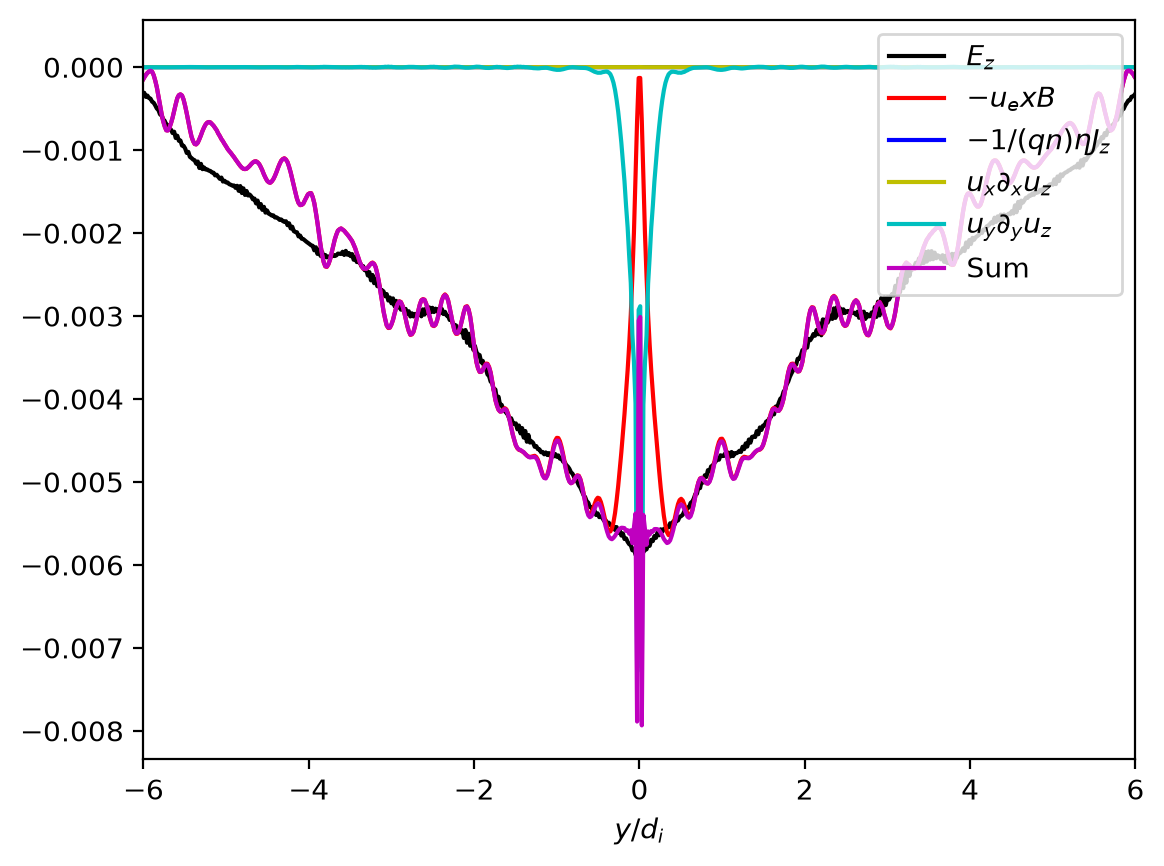

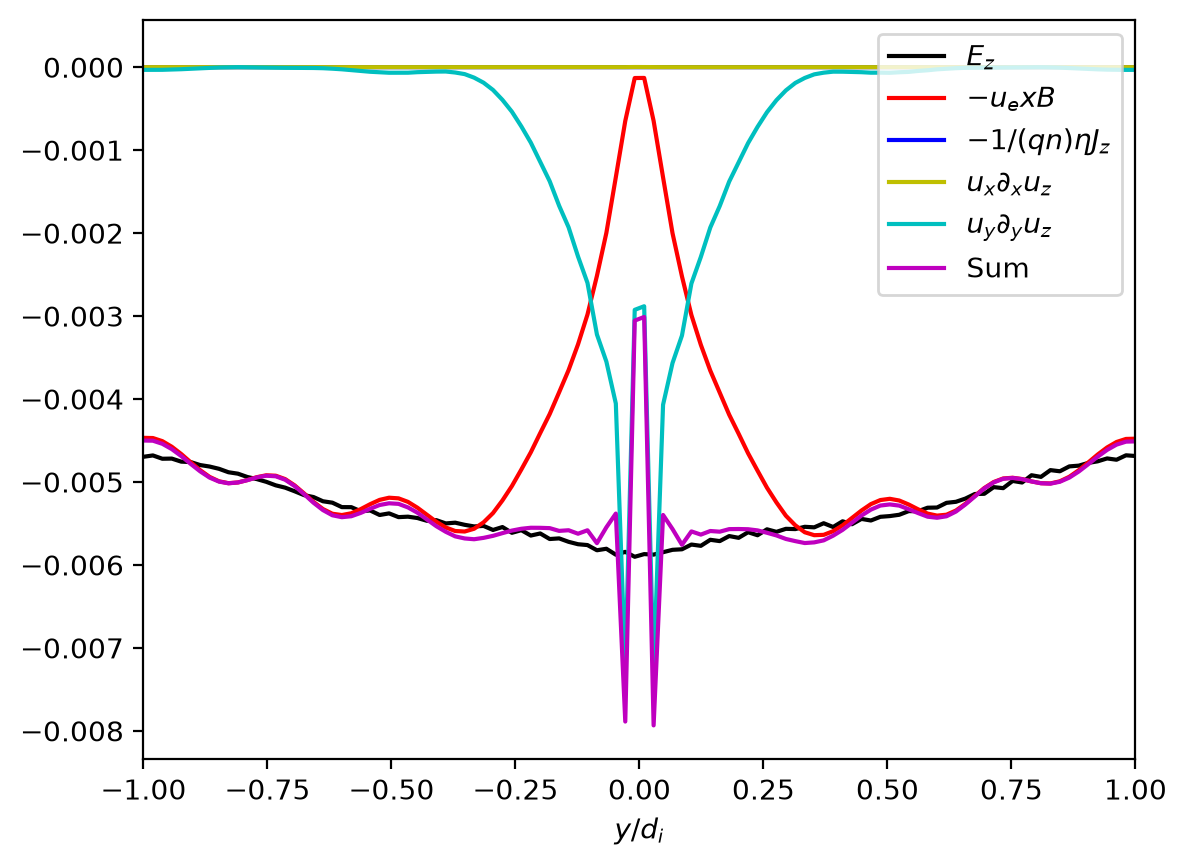

In [ ]:
_coords, _Ez, _hallz, eta_z, _divRxz_elc, _divRyz_elc = ohm_5m(40)
_sum_ohm = -_hallz - eta_z + _divRxz_elc + _divRyz_elc
_x_point = int(Nx_1 / 2)
plt.figure()
plt.plot(_coords[1] / di, _Ez[_x_point, :], 'k', label='$E_z$')
plt.plot(_coords[1] / di, -_hallz[_x_point, :], 'r', label='$-u_e x B$')
plt.plot(_coords[1] / di, -eta_z[_x_point, :], 'b', label='$-1/(qn) \\eta J_z$')
plt.plot(_coords[1] / di, _divRxz_elc[_x_point, :], 'y', label='$u_x \\partial_x u_z$')
plt.plot(_coords[1] / di, _divRyz_elc[_x_point, :], 'c', label='$u_y \\partial_y u_z$')
plt.plot(_coords[1] / di, _sum_ohm[_x_point, :], 'm', label='Sum')
plt.xlabel('$y/d_i$')
plt.legend(loc='upper right')
plt.xlim(-6.0, 6.0)
plt.figure()
plt.plot(_coords[1] / di, _Ez[_x_point, :], 'k', label='$E_z$')
plt.plot(_coords[1] / di, -_hallz[_x_point, :], 'r', label='$-u_e x B$')
plt.plot(_coords[1] / di, -eta_z[_x_point, :], 'b', label='$-1/(qn) \\eta J_z$')
plt.plot(_coords[1] / di, _divRxz_elc[_x_point, :], 'y', label='$u_x \\partial_x u_z$')
plt.plot(_coords[1] / di, _divRyz_elc[_x_point, :], 'c', label='$u_y \\partial_y u_z$')
plt.plot(_coords[1] / di, _sum_ohm[_x_point, :], 'm', label='Sum')
plt.xlabel('$y/d_i$')
plt.legend(loc='upper right')
plt.xlim(-1.0, 1.0)
plt.show()

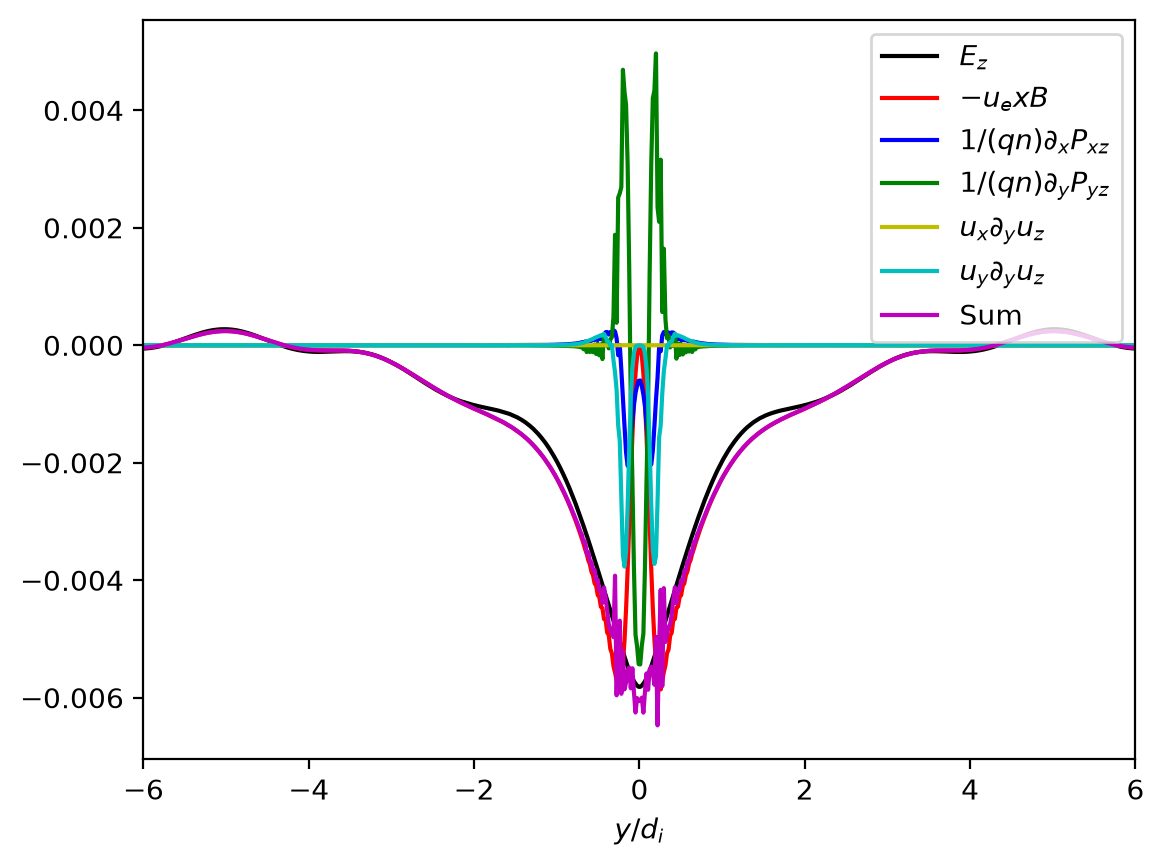

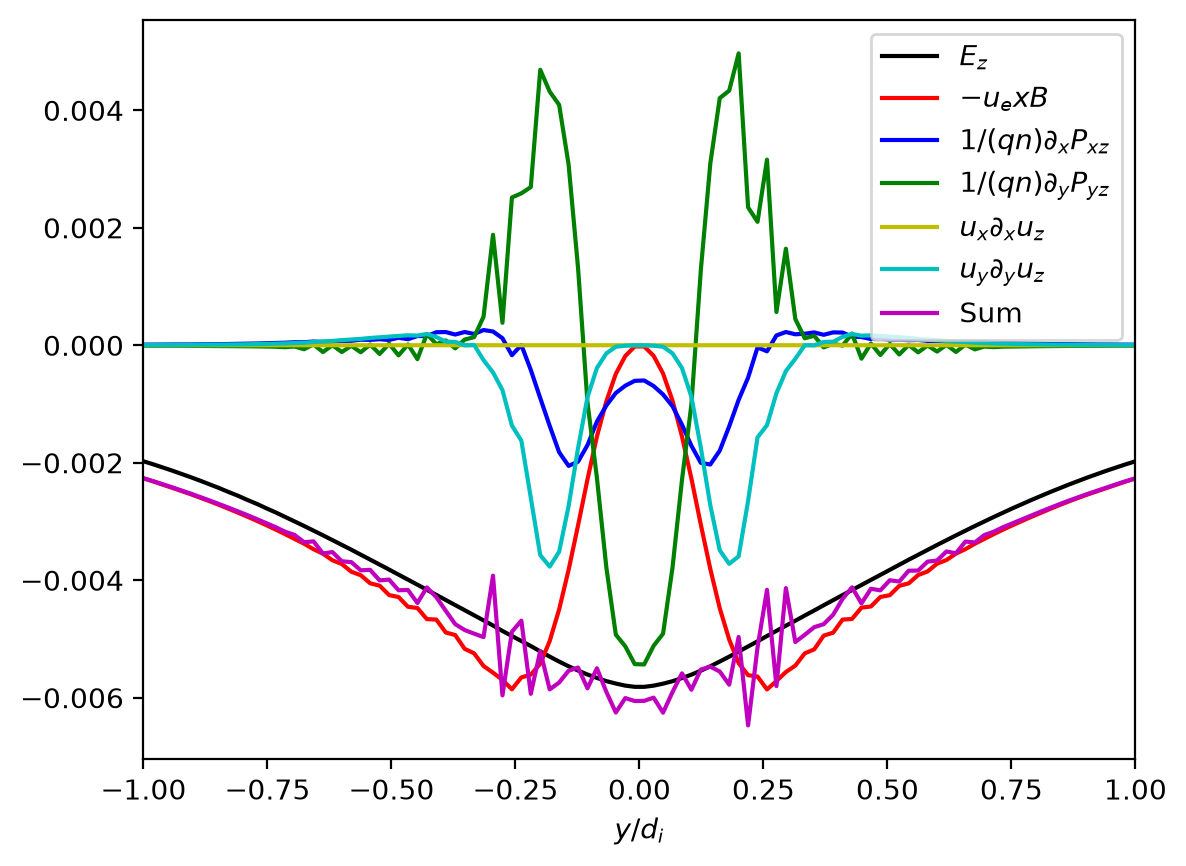

In [ ]:
_coords, _Ez, _hallz, divPxz_elc, divPyz_elc, _divRxz_elc, _divRyz_elc = ohm_10m(40)
_sum_ohm = -_hallz + divPxz_elc + divPyz_elc + _divRxz_elc + _divRyz_elc
_x_point = int(Nx_1 / 2)
plt.figure()
plt.plot(_coords[1] / di, _Ez[_x_point, :], 'k', label='$E_z$')
plt.plot(_coords[1] / di, -_hallz[_x_point, :], 'r', label='$-u_e x B$')
plt.plot(_coords[1] / di, divPxz_elc[_x_point, :], 'b', label='$1/(qn) \\partial_x P_{xz}$')
plt.plot(_coords[1] / di, divPyz_elc[_x_point, :], 'g', label='$1/(qn) \\partial_y P_{yz}$')
plt.plot(_coords[1] / di, _divRxz_elc[_x_point, :], 'y', label='$u_x \\partial_y u_z$')
plt.plot(_coords[1] / di, _divRyz_elc[_x_point, :], 'c', label='$u_y \\partial_y u_z$')
plt.plot(_coords[1] / di, _sum_ohm[_x_point, :], 'm', label='Sum')
plt.xlabel('$y/d_i$')
plt.legend(loc='upper right')
plt.xlim(-6.0, 6.0)
plt.figure()
plt.plot(_coords[1] / di, _Ez[_x_point, :], 'k', label='$E_z$')
plt.plot(_coords[1] / di, -_hallz[_x_point, :], 'r', label='$-u_e x B$')
plt.plot(_coords[1] / di, divPxz_elc[_x_point, :], 'b', label='$1/(qn) \\partial_x P_{xz}$')
plt.plot(_coords[1] / di, divPyz_elc[_x_point, :], 'g', label='$1/(qn) \\partial_y P_{yz}$')
plt.plot(_coords[1] / di, _divRxz_elc[_x_point, :], 'y', label='$u_x \\partial_x u_z$')
plt.plot(_coords[1] / di, _divRyz_elc[_x_point, :], 'c', label='$u_y \\partial_y u_z$')
plt.plot(_coords[1] / di, _sum_ohm[_x_point, :], 'm', label='Sum')
plt.xlabel('$y/d_i$')
plt.legend(loc='upper right')
plt.xlim(-1.0, 1.0)
plt.show()